### Neural Network from Scratch

In [283]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import numpy as np
import copy

Load Dataset

In [284]:
X, Y = make_moons(
    n_samples=1000,
    noise=0.1,
    random_state=42
)

Y = Y.reshape(-1, 1)

X.shape, Y.shape

((1000, 2), (1000, 1))

In [285]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).T
X_test = scaler.transform(X_test).T

Y_train = Y_train.T
Y_test = Y_test.T

X_train.shape, Y_train.shape, X_test.shape, Y_test.shape

((2, 800), (1, 800), (2, 200), (1, 200))

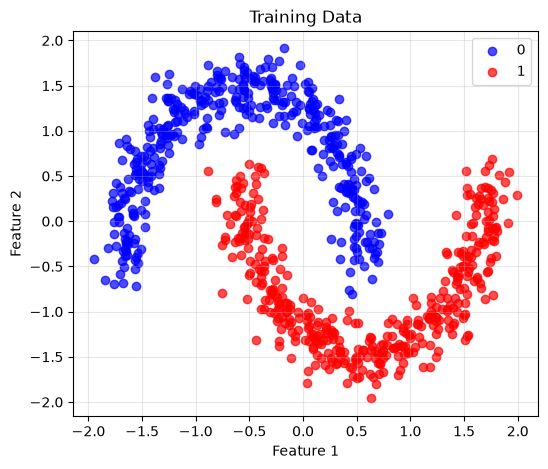

In [286]:
y_train = Y_train.ravel()

plt.figure(figsize=(6, 5))
plt.scatter(X_train[0, y_train == 0], X_train[1, y_train == 0], c='blue', label='0', alpha=0.7)
plt.scatter(X_train[0, y_train == 1], X_train[1, y_train == 1], c='red', label='1', alpha=0.7)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Training Data')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Initialize Parameters

In [287]:
def initialize_parameters(n_x, layer_dims):
    np.random.seed(42)
    parameters = {}
    layer_dims = [n_x] + layer_dims
    L = len(layer_dims)

    for l in range(1, L):
        parameters['W' + str(l)] = (
            np.random.randn(layer_dims[l], layer_dims[l - 1]) 
            * np.sqrt(2 / layer_dims[l - 1])
        )
        
        parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))

    return parameters

Activation Functions

In [288]:
def sigmoid(Z):
    return 1 / (1 + np.exp(-Z))

def relu(Z):
    return np.maximum(0, Z)

Forward Propagation

In [289]:
def linear_activation_forward(A_prev, W, b, activation='relu'):
    Z = np.dot(W, A_prev) + b
    A = None
    
    if activation == 'relu':
        A = relu(Z)
    elif activation == 'sigmoid':
        A = sigmoid(Z)
        
    return A, Z

In [290]:
def forward_propagation(X, parameters, layer_dims):
    L = len(layer_dims)
    cache = {}

    A_prev = X
    cache['A0'] = X

    for l in range(1, L):
        W = parameters['W' + str(l)]
        b = parameters['b' + str(l)]
        
        A, Z = linear_activation_forward(A_prev, W, b, 'relu')
        cache['A' + str(l)] = A
        cache['Z' + str(l)] = Z
        
        A_prev = A
        
    WL = parameters['W' + str(L)]
    bL = parameters['b' + str(L)]

    AL, ZL = linear_activation_forward(A_prev, WL, bL, 'sigmoid')
    cache['A' + str(L)] = AL
    cache['Z' + str(L)] = ZL

    return AL, cache

ReLU Derivative Function

In [291]:
def relu_derivative(Z):
    return (Z > 0).astype(float)

Back Propagation

In [292]:
def linear_activation_backward(Y, dA, A, A_prev, Z, W, activation='relu'):
    m = Y.shape[1]
    
    if activation == 'sigmoid':
        dZ = A - Y
    elif activation == 'relu':
        dZ = np.multiply(dA, relu_derivative(Z))
        
    dW = np.dot(dZ, A_prev.T) / m 
    db = np.sum(dZ, axis=1, keepdims=True) / m
    
    dA_prev = np.dot(W.T, dZ)
    
    return dW, db, dA_prev

In [293]:
def back_propagation(Y, parameters, cache, layer_dims):
    grads = {}
    
    L = len(layer_dims)
    
    AL = cache['A' + str(L)]
    ZL = cache['Z' + str(L)]
    A_prev = cache['A' + str(L - 1)]
    WL = parameters['W' + str(L)]
    
    # dAL = - np.divide(Y, AL) + np.divide(1 - Y, 1 - AL)
    
    dWL, dbL, dA_prev = linear_activation_backward(Y, 'dAL', AL, A_prev, ZL, WL, activation='sigmoid')
    
    grads['dW' + str(L)] = dWL
    grads['db' + str(L)] = dbL
    
    
    for l in range(L - 1, 0, -1):
        dA = dA_prev
        W = parameters['W' + str(l)]
        A_prev = cache['A' + str(l - 1)]
        Z = cache['Z' + str(l)]
        
        dW, db, dA_prev = linear_activation_backward(Y, dA, 'A', A_prev, Z, W, activation='relu')
        
        grads['dW' + str(l)] = dW
        grads['db' + str(l)] = db
        
    return grads

Compute Cost

In [294]:
def compute_cost(A, Y):
    m = Y.shape[1]
    
    cost = - np.sum(np.multiply(Y, np.log(A)) + np.multiply(1 - Y, np.log(1 - A))) / m
    
    cost = np.squeeze(cost)
    
    return cost

Update Parameters

In [295]:
def update_parameters(params, grads, learning_rate=0.0075):
    L = len(params) // 2
    
    parameters = copy.deepcopy(params)
    
    for l in range(L):
        parameters['W' + str(l + 1)] -= learning_rate * grads['dW' + str(l + 1)]
        parameters['b' + str(l + 1)] -= learning_rate * grads['db' + str(l + 1)]
        
    return parameters

Neural Network Model

In [296]:
def deep_nn_model(X, Y, layer_dims, num_iterations=3000, learning_rate=0.0075):
    np.random.seed(42)
    costs = []
    
    input_dim = X.shape[0]
    
    parameters = initialize_parameters(input_dim, layer_dims)
    
    for i in range(num_iterations):
        AL, cache = forward_propagation(X, parameters, layer_dims)
        
        cost = compute_cost(AL, Y)
        
        grads = back_propagation(Y, parameters, cache, layer_dims)
        
        parameters = update_parameters(parameters, grads, learning_rate)
        
        if i % 100 == 0 or i == num_iterations - 1:
            print("Cost after iteration {}: {}".format(i, np.squeeze(cost)))
            costs.append(cost)
            
    return parameters, costs

Train the Model

In [303]:
layer_dims = [20, 30, 30, 20, 5, 1]

parameters, costs = deep_nn_model(X_train, Y_train, layer_dims, num_iterations=3000, learning_rate=0.0075)

Cost after iteration 0: 0.7561366590974881
Cost after iteration 100: 0.47339932204121865
Cost after iteration 200: 0.427643740870394
Cost after iteration 300: 0.39844344457634423
Cost after iteration 400: 0.37562890029069435
Cost after iteration 500: 0.3566762120687564
Cost after iteration 600: 0.3405511324582027
Cost after iteration 700: 0.326914784782945
Cost after iteration 800: 0.31531248230787035
Cost after iteration 900: 0.3051462909607354
Cost after iteration 1000: 0.2959991878536596
Cost after iteration 1100: 0.28702395671171277
Cost after iteration 1200: 0.27888209368608885
Cost after iteration 1300: 0.27226812530221506
Cost after iteration 1400: 0.26628552778156517
Cost after iteration 1500: 0.260635561631021
Cost after iteration 1600: 0.2550692322638395
Cost after iteration 1700: 0.24995093049600756
Cost after iteration 1800: 0.2447242252865385
Cost after iteration 1900: 0.23902600797165718
Cost after iteration 2000: 0.23311142360066983
Cost after iteration 2100: 0.226030668

Calculate Perfomance on Test Set

In [306]:
train_probabilities, _ = forward_propagation(X_train, parameters, layer_dims)
Y_train_pred = (train_probabilities >= 0.5).astype(int)
test_probabilities, _ = forward_propagation(X_test, parameters, layer_dims)
Y_pred = (test_probabilities >= 0.5).astype(int)

y_train = Y_train.ravel()
y_train_pred = Y_train_pred.ravel()
y_test = Y_test.ravel()
y_pred = Y_pred.ravel()

print(f"Train accuracy: {accuracy_score(y_train, y_train_pred):.2%}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.2%}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Train accuracy: 99.50%
Test accuracy: 100.00%

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       100
           1       1.00      1.00      1.00       100

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200

Confusion matrix:
[[100   0]
 [  0 100]]


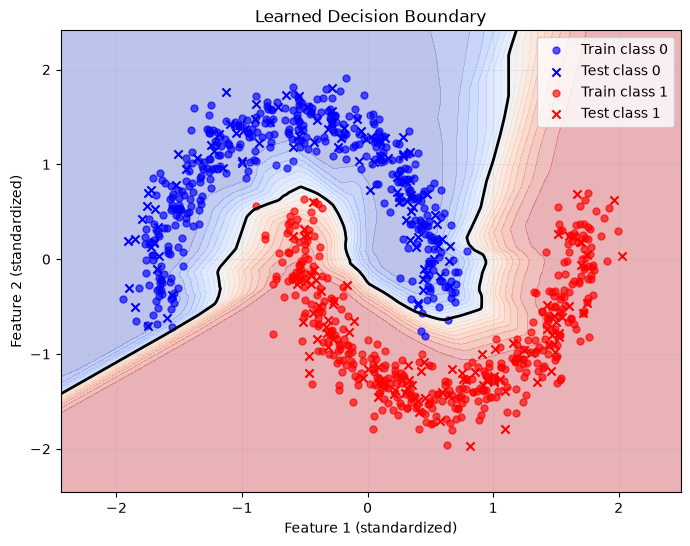

In [305]:
x_min, x_max = X_train[0].min() - 0.5, X_train[0].max() + 0.5
y_min, y_max = X_train[1].min() - 0.5, X_train[1].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300),
)

mesh_points = np.vstack((xx.ravel(), yy.ravel()))
mesh_probabilities, _ = forward_propagation(mesh_points, parameters, layer_dims)
mesh_probabilities = mesh_probabilities.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, mesh_probabilities, levels=20, cmap="coolwarm", alpha=0.35)
plt.contour(xx, yy, mesh_probabilities, levels=[0.5], colors="black", linewidths=2)

for label, color in [(0, "blue"), (1, "red")]:
    train_mask = Y_train.ravel() == label
    test_mask = Y_test.ravel() == label
    plt.scatter(
        X_train[0, train_mask], X_train[1, train_mask],
        c=color, label=f"Train class {label}", alpha=0.65, s=25,
    )
    plt.scatter(
        X_test[0, test_mask], X_test[1, test_mask],
        c=color, marker="x", label=f"Test class {label}", s=35,
    )

plt.xlabel("Feature 1 (standardized)")
plt.ylabel("Feature 2 (standardized)")
plt.title("Learned Decision Boundary")
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()

### What I Learned

Used 0.01 scaling for ReLU layer weight initialization

- with multiple Relu hidden layers, activations shrank sharply
- output probs were all very close to 0.5
- this led to tiny gradients for the weights -> almost no progress
- **Solution** - He initialization sqrt(2/n_prev)

Weights initialized unscaled for relu layers

- hidden activations grew large, pushing output sigmoid to exactly 1.0
- caused division by zero in dAL
